# SV5 Nguyễn Minh Triết — #16: Phân tích lỗi (RQ4), #17: Diễn giải mô hình (RQ2)

Chạy sau `04_timepoint.ipynb`. Phân tích **RF-C tham chiếu** bằng dự đoán OOF
trên 3.539 dòng train; không phân tích dự đoán in-sample hoặc đánh giá hold-out.
Pipeline được fit lại từng fold để tính importance; permutation chỉ trên validation.
Kết quả sau lựa chọn tham số trên cùng train có thể lạc quan, chưa thay kết quả cuối #18.

Giữ hình, nhận xét và hướng dẫn tái lập trong notebook. Các bảng CSV lưu kết quả
chi tiết để đối chiếu. Không sửa pipeline chung, model của nhóm hoặc issue #14.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/config.py").is_file() and (p / "src/data.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src import config
from src.data import load_data, get_train_test
from src.evaluate import get_cv, compute_metrics, report, confusion
from src.preprocessing import build_pipeline, get_feature_names
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
pd.set_option("display.max_columns", 20)
REPORTS = ROOT / "reports"
DATA_HASH = hashlib.sha256(config.DATA_FILE.read_bytes()).hexdigest()
rf_source = json.loads((REPORTS / "rf_summary.json").read_text(encoding="utf-8"))
assert DATA_HASH == rf_source["data_sha256"], "Dữ liệu khác lượt tuning RF được bàn giao"
gb_source = pd.read_csv(REPORTS / "gb_search_results.csv").sort_values("rank_test_score").iloc[0]
svm_source = pd.read_csv(REPORTS / "svm_search_results.csv").sort_values("rank_test_score").iloc[0]
PARAMS = {
    "RF": {k.removeprefix("clf__"): v for k, v in rf_source["best_params"].items()},
    "GB": {"n_estimators": int(gb_source["param_clf__n_estimators"]),
           "learning_rate": float(gb_source["param_clf__learning_rate"]),
           "max_depth": int(gb_source["param_clf__max_depth"]),
           "subsample": float(gb_source["param_clf__subsample"])},
    "SVM": {"C": float(svm_source["param_clf__C"]),
            "kernel": str(svm_source["param_clf__kernel"]),
            "gamma": float(svm_source["param_clf__gamma"]),
            "class_weight": str(svm_source["param_clf__class_weight"])},
}
def make_model(name, feature_set):
    estimator = {
        "RF": lambda: RandomForestClassifier(**PARAMS["RF"], random_state=config.RANDOM_STATE, n_jobs=1),
        "GB": lambda: GradientBoostingClassifier(**PARAMS["GB"], random_state=config.RANDOM_STATE),
        "SVM": lambda: SVC(**PARAMS["SVM"], random_state=config.RANDOM_STATE),
    }[name]()
    return build_pipeline(estimator, feature_set, scale=(name == "SVM"))

X, holdout, y, holdout_y = get_train_test("C")
HOLDOUT_IDS = set(holdout.index)
del holdout, holdout_y
assert len(X) == 3539 and len(HOLDOUT_IDS) == 885
assert not set(X.index) & HOLDOUT_IDS
folds = list(get_cv().split(X, y))
coverage = np.zeros(len(X), dtype=int)
for tr, va in folds:
    assert not set(tr) & set(va)
    coverage[va] += 1
assert np.all(coverage == 1)
VERSIONS = {p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn", "joblib", "matplotlib"]}
PROVENANCE = {"python": platform.python_version(), "versions": VERSIONS,
              "data_sha256": DATA_HASH, "seed": config.RANDOM_STATE,
              "folds": config.N_SPLITS, "train_rows": len(X), "holdout_rows_reserved": len(HOLDOUT_IDS),
              "parameters": PARAMS,
              "source_sha256": {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
                   for p in [ROOT / "src/config.py", ROOT / "src/data.py", ROOT / "src/features.py",
                             ROOT / "src/preprocessing.py", ROOT / "src/evaluate.py",
                             REPORTS / "rf_summary.json", REPORTS / "gb_search_results.csv",
                             REPORTS / "svm_search_results.csv"]}}
print(json.dumps(PROVENANCE, ensure_ascii=False, indent=2))

# Mỗi lần Restart & Run All tạo một thư mục minh chứng mới ngoài repo.
import os, shutil, subprocess, io, base64, time
from datetime import datetime
from zoneinfo import ZoneInfo
import nbformat
STARTED = datetime.now(ZoneInfo("Asia/Ho_Chi_Minh"))
RUN_ID = STARTED.strftime("%Y%m%d_SV5_ANALYSIS_%H%M%S_%f")
# Để trống SV5_OUTPUT_DIR để dùng đường dẫn mặc định; nếu đặt, thư mục phải mới/rỗng.
OUTPUT = Path(os.environ.get("SV5_OUTPUT_DIR") or
              Path.home() / "Documents" / "MLGroup_SV5" / "runs" / RUN_ID).resolve()
if OUTPUT == ROOT or ROOT in OUTPUT.parents:
    raise ValueError("Minh chứng phải nằm ngoài repo.")
if OUTPUT.exists() and (not OUTPUT.is_dir() or any(OUTPUT.iterdir())):
    raise ValueError("Thư mục minh chứng đã có dữ liệu; chọn thư mục mới để tránh ghi đè.")
OUTPUT.mkdir(parents=True, exist_ok=True)
def sha(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()
def notebook_code_hash(path):
    notebook = nbformat.read(path, as_version=4)
    code = "\n".join(c.source for c in notebook.cells if c.cell_type == "code")
    return hashlib.sha256(code.encode("utf-8")).hexdigest()
def git_value(*args):
    return subprocess.check_output(["git", *args], cwd=ROOT, text=True, encoding="utf-8").strip()
MODEL_HASHES = {p.name: sha(p) for p in (ROOT / "models").glob("*.joblib")}
INPUT_CSV_HASHES = {name: sha(REPORTS / name) for name in ["timepoint_cv.csv", "rf_oof.csv"]}
FIGURE_BYTES = {}
def capture_figure(fig, name):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=110, bbox_inches="tight")
    FIGURE_BYTES[name] = buffer.getvalue()
METADATA = {
    **PROVENANCE, "run_id": RUN_ID, "started_at": STARTED.isoformat(),
    "executor": os.environ.get("SV5_EXECUTOR", "Chưa khai báo; người chạy điền khi bàn giao"),
    "python_executable": sys.executable, "git_commit_at_start": git_value("rev-parse", "HEAD"),
    "git_status_at_start": git_value("status", "--short"),
    "notebook_code_sha256": {name: notebook_code_hash(ROOT / "notebooks" / name)
                             for name in ["04_timepoint.ipynb", "05_error_analysis.ipynb"]},
    "requirements_sha256": sha(ROOT / "requirements.txt"),
    "input_csv_sha256": INPUT_CSV_HASHES, "shared_model_hashes_before": MODEL_HASHES,
    "scope": "Train-only 5-fold CV / OOF / validation; parameters chosen on C, fixed across A/B/C.",
    "holdout_evaluated": False, "models": ["RF", "GB", "SVM"],
    "missing_model_handoffs": ["LR", "DT"], "checks": {}, "status": "running",
}
(OUTPUT / "metadata.json").write_text(json.dumps(METADATA, ensure_ascii=False, indent=2), encoding="utf-8")
print("Minh chứng:", OUTPUT)


{
  "python": "3.12.10",
  "versions": {
    "numpy": "2.5.4",
    "pandas": "3.1.1",
    "scipy": "1.18.1",
    "scikit-learn": "1.9.1",
    "joblib": "1.6.0",
    "matplotlib": "3.11.2"
  },
  "data_sha256": "edc197d1381f25414a3757ab9bbae5f1f6d21aa6a964dbe98a148c15f3d63036",
  "seed": 42,
  "folds": 5,
  "train_rows": 3539,
  "holdout_rows_reserved": 885,
  "parameters": {
    "RF": {
      "n_estimators": 100,
      "min_samples_split": 10,
      "min_samples_leaf": 2,
      "max_features": "sqrt",
      "max_depth": null,
      "class_weight": "balanced"
    },
    "GB": {
      "n_estimators": 200,
      "learning_rate": 0.05,
      "max_depth": 4,
      "subsample": 0.85
    },
    "SVM": {
      "C": 10.0,
      "kernel": "rbf",
      "gamma": 0.003,
      "class_weight": "balanced"
    }
  },
  "source_sha256": {
    "src\\config.py": "46c4bc6cf6dbaf484eb7e40bb182dd544bdcc24f55c24cd47e373689c1de402b",
    "src\\data.py": "5923ac69745b8dbc392f862d9e70c0ca1aa153bcd222e1db6ebeacc2

Minh chứng: C:\Users\Admin\Documents\MLGroup_SV5\runs\20261115_SV5_ANALYSIS_105647_898466


## 1. Đọc và xác minh dự đoán OOF của RF-C

`row_id` là chỉ số dòng sau nạp dữ liệu, không phải mã sinh viên.
Xác suất RF chưa được hiệu chỉnh; chỉ dùng mô tả lỗi, không đặt ngưỡng can thiệp.

              precision    recall  f1-score   support

     Dropout      0.853     0.731     0.787      1137
    Enrolled      0.485     0.620     0.544       635
    Graduate      0.849     0.842     0.846      1767

    accuracy                          0.767      3539
   macro avg      0.729     0.731     0.726      3539
weighted avg      0.785     0.767     0.773      3539



,pred_Dropout,pred_Enrolled,pred_Graduate
true_Dropout,831,194,112
true_Enrolled,89,394,152
true_Graduate,54,225,1488


Pooled OOF metrics (khác trung bình độ đo từng fold):


f1_macro              0.7257
balanced_accuracy     0.7311
accuracy              0.7666
precision_Dropout     0.8532
recall_Dropout        0.7309
f1_Dropout            0.7873
precision_Enrolled    0.4846
recall_Enrolled       0.6205
f1_Enrolled           0.5442
precision_Graduate    0.8493
recall_Graduate       0.8421
f1_Graduate           0.8457
dtype: float64

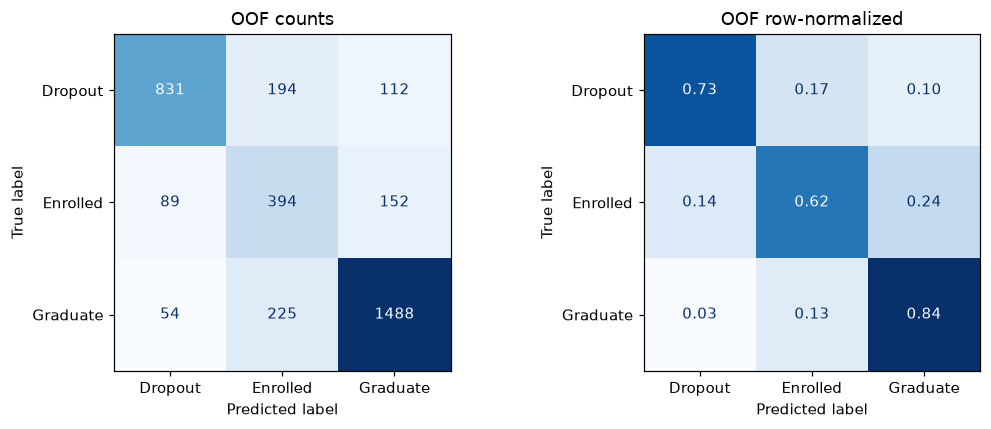

In [2]:
cv_table = pd.read_csv(REPORTS / "timepoint_cv.csv")
assert cv_table.data_sha256.eq(DATA_HASH).all()
assert len(cv_table) == 45
oof = pd.read_csv(REPORTS / "rf_oof.csv").set_index("row_id")
assert oof.index.is_unique and set(oof.index) == set(X.index)
assert not set(oof.index) & HOLDOUT_IDS
assert (oof.actual == y.loc[oof.index]).all()
for fold, (_, va) in enumerate(folds, 1):
    assert set(oof.index[oof.fold.eq(fold)]) == set(X.index[va])
analysis = X.join(oof).copy()
analysis["error"] = analysis.actual.ne(analysis.predicted)
print(report(analysis.actual, analysis.predicted))
display(confusion(analysis.actual, analysis.predicted))
print("Pooled OOF metrics (khác trung bình độ đo từng fold):")
display(pd.Series(compute_metrics(analysis.actual, analysis.predicted)).round(4))
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, normalize, fmt, title in [(axes[0], None, "d", "OOF counts"),
                                  (axes[1], "true", ".2f", "OOF row-normalized")]:
    ConfusionMatrixDisplay.from_predictions(analysis.actual, analysis.predicted,
        labels=config.CLASSES, normalize=normalize, values_format=fmt,
        cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(title)
fig.tight_layout()
capture_figure(fig, "02_rf_oof_confusion.png")
plt.show()

## 2. Enrolled bị nhầm sang đâu? Sai số theo nhóm

Mỗi nhóm chỉ trình bày nếu có ít nhất 20 sinh viên Enrolled. Đây là mô tả thăm dò;
các nhóm chồng lấp, nhiều so sánh và không điều chỉnh yếu tố gây nhiễu.
Không coi các tỷ lệ dưới đây là bằng chứng nhân quả hoặc quy tắc ra quyết định.

,n
prediction_group,
Correct Enrolled,394
Enrolled → Dropout,89
Enrolled → Graduate,152


,group,value,n_Enrolled,error_rate,to_Dropout,to_Graduate
9,Age group,21–25,143,0.3147,0.1538,0.1608
10,Age group,>25,113,0.5398,0.2212,0.3186
8,Age group,≤20,379,0.3562,0.1108,0.2454
11,Course,171,27,0.8148,0.6296,0.1852
12,Course,9003,31,0.5484,0.2581,0.2903
13,Course,9070,32,0.4062,0.0312,0.3750
14,Course,9085,63,0.2222,0.1111,0.1111
15,Course,9119,53,0.3962,0.2642,0.1321
16,Course,9147,91,0.2747,0.1758,0.0989
17,Course,9238,30,0.3333,0.1333,0.2000


,Age at enrollment,Admission grade,Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade)
prediction_group,,,,,,
Correct Enrolled,20.0,123.30,4.0,12.00,4.0,11.80
Enrolled → Dropout,21.0,123.00,1.0,10.00,0.0,0.00
Enrolled → Graduate,20.0,125.45,6.0,12.85,6.0,12.75


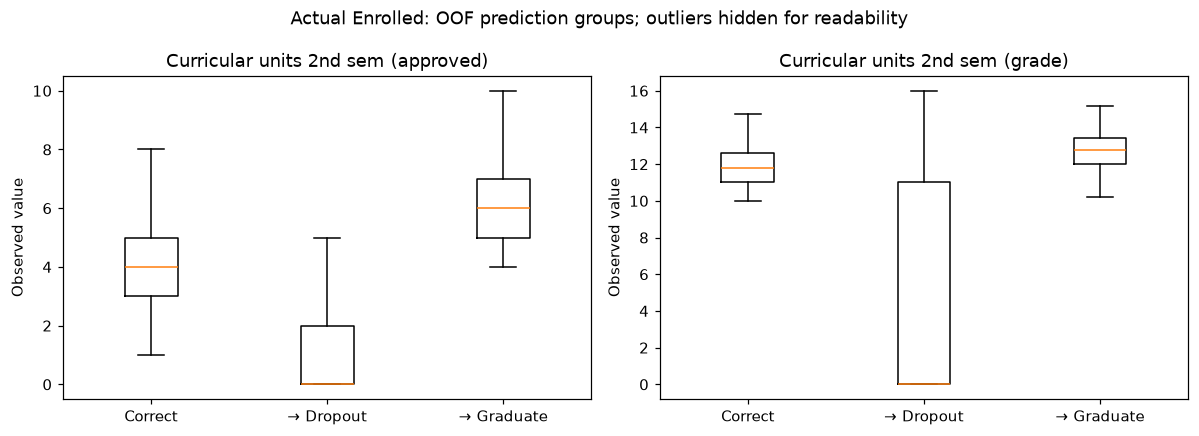

Ví dụ mô tả: 5 dòng Enrolled sai có xác suất lớp dự đoán cao nhất, không dùng để tuning.


,actual,predicted,prob_Dropout,prob_Enrolled,prob_Graduate,Course,Scholarship holder,Tuition fees up to date,Age at enrollment,Admission grade,Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade)
2794,Enrolled,Dropout,0.993,0.005,0.002,9991,0,1,29,127.6,0,0.000,0,0.000
643,Enrolled,Graduate,0.020,0.011,0.969,9500,0,1,18,133.8,8,14.269,8,14.269
358,Enrolled,Dropout,0.936,0.063,0.002,9003,1,1,30,130.0,0,0.000,0,0.000
1650,Enrolled,Graduate,0.042,0.024,0.934,9500,0,1,19,124.3,7,14.514,7,14.514
3077,Enrolled,Dropout,0.928,0.071,0.002,9119,0,0,27,128.0,0,0.000,0,0.000


In [3]:
enrolled = analysis.loc[analysis.actual.eq("Enrolled")].copy()
enrolled["prediction_group"] = enrolled.predicted.map({"Enrolled": "Correct Enrolled", "Dropout": "Enrolled → Dropout", "Graduate": "Enrolled → Graduate"})
display(enrolled.groupby("prediction_group").size().rename("n").to_frame())
analysis["Age group"] = pd.cut(analysis["Age at enrollment"], [0, 20, 25, 100], labels=["≤20", "21–25", ">25"])
group_cols = ["Scholarship holder", "Tuition fees up to date", "Debtor", "Gender", "Age group", "Course"]
slices = []
for col in group_cols:
    for value, sub in analysis.loc[analysis.actual.eq("Enrolled")].groupby(col, observed=True):
        if len(sub) >= 20:
            slices.append({"group": col, "value": str(value), "n_Enrolled": len(sub),
                           "error_rate": sub.error.mean(),
                           "to_Dropout": sub.predicted.eq("Dropout").mean(),
                           "to_Graduate": sub.predicted.eq("Graduate").mean()})
slice_table = pd.DataFrame(slices).sort_values(["group", "value"])
display(slice_table.round(4))
profile_cols = ["Age at enrollment", "Admission grade", "Curricular units 1st sem (approved)",
                "Curricular units 1st sem (grade)", "Curricular units 2nd sem (approved)",
                "Curricular units 2nd sem (grade)"]
display(enrolled.groupby("prediction_group")[profile_cols].median().round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
categories = ["Correct Enrolled", "Enrolled → Dropout", "Enrolled → Graduate"]
for ax, column in zip(axes, ["Curricular units 2nd sem (approved)", "Curricular units 2nd sem (grade)"]):
    data = [enrolled.loc[enrolled.prediction_group.eq(c), column] for c in categories]
    ax.boxplot(data, tick_labels=["Correct", "→ Dropout", "→ Graduate"], showfliers=False)
    ax.set(title=column, ylabel="Observed value")
fig.suptitle("Actual Enrolled: OOF prediction groups; outliers hidden for readability")
fig.tight_layout()
capture_figure(fig, "03_enrolled_errors.png")
plt.show()
case_columns = ["actual", "predicted", "prob_Dropout", "prob_Enrolled", "prob_Graduate", "Course",
                "Scholarship holder", "Tuition fees up to date", *profile_cols]
print("Ví dụ mô tả: 5 dòng Enrolled sai có xác suất lớp dự đoán cao nhất, không dùng để tuning.")
wrong = analysis.loc[analysis.actual.eq("Enrolled") & analysis.error].copy()
wrong["max_probability"] = wrong[[f"prob_{c}" for c in config.CLASSES]].max(axis=1)
display(wrong.sort_values("max_probability", ascending=False)[case_columns].head(5).round(3))

## 3. Importance của RF: tính trong từng fold, validation tách khỏi fit

**Impurity importance:** cộng các cột One-Hot về biến gốc; giữ riêng các biến tạo thêm.
Đây là độ quan trọng nội tại, có thiên lệch với biến nhiều giá trị/tương quan.

**Permutation importance:** hoán vị từng biến gốc trên validation, 5 lần mỗi fold;
độ đo là mức giảm Macro-F1. Hoán vị trước bước tạo đặc trưng nên các biến tỷ lệ/điểm
phái sinh được tính lại từ dữ liệu bị hoán vị. Có thể tạo tổ hợp giá trị không tự nhiên;
biến tương quan chia sẻ tín hiệu nên importance thấp không chứng minh biến vô ích.
Hai phương pháp có đơn vị khác nhau, không so trực tiếp trị số.

RF-C: importance fold 1/5 hoàn tất


RF-C: importance fold 2/5 hoàn tất


RF-C: importance fold 3/5 hoàn tất


RF-C: importance fold 4/5 hoàn tất


RF-C: importance fold 5/5 hoàn tất


**RF grouped impurity importance**

,mean,std
feature,,
Pass rate 2nd sem,0.11794,0.01199
Curricular units 2nd sem (approved),0.08854,0.00954
Curricular units 2nd sem (grade),0.07547,0.00633
Pass rate 1st sem,0.07196,0.00698
Curricular units 1st sem (approved),0.05318,0.00623
Curricular units 1st sem (grade),0.05098,0.00400
Tuition fees up to date,0.04156,0.00342
Course,0.04119,0.00190
Curricular units 2nd sem (evaluations),0.03405,0.00248


**Validation permutation: decrease in Macro-F1**

,mean,std
feature,,
Curricular units 2nd sem (approved),0.15112,0.01333
Curricular units 1st sem (approved),0.05411,0.01577
Tuition fees up to date,0.03528,0.00606
Curricular units 2nd sem (grade),0.03399,0.00728
Curricular units 2nd sem (enrolled),0.02896,0.00828
Curricular units 1st sem (enrolled),0.01852,0.00410
Course,0.01245,0.00332
Age at enrollment,0.01089,0.00447
Curricular units 2nd sem (evaluations),0.00767,0.00354


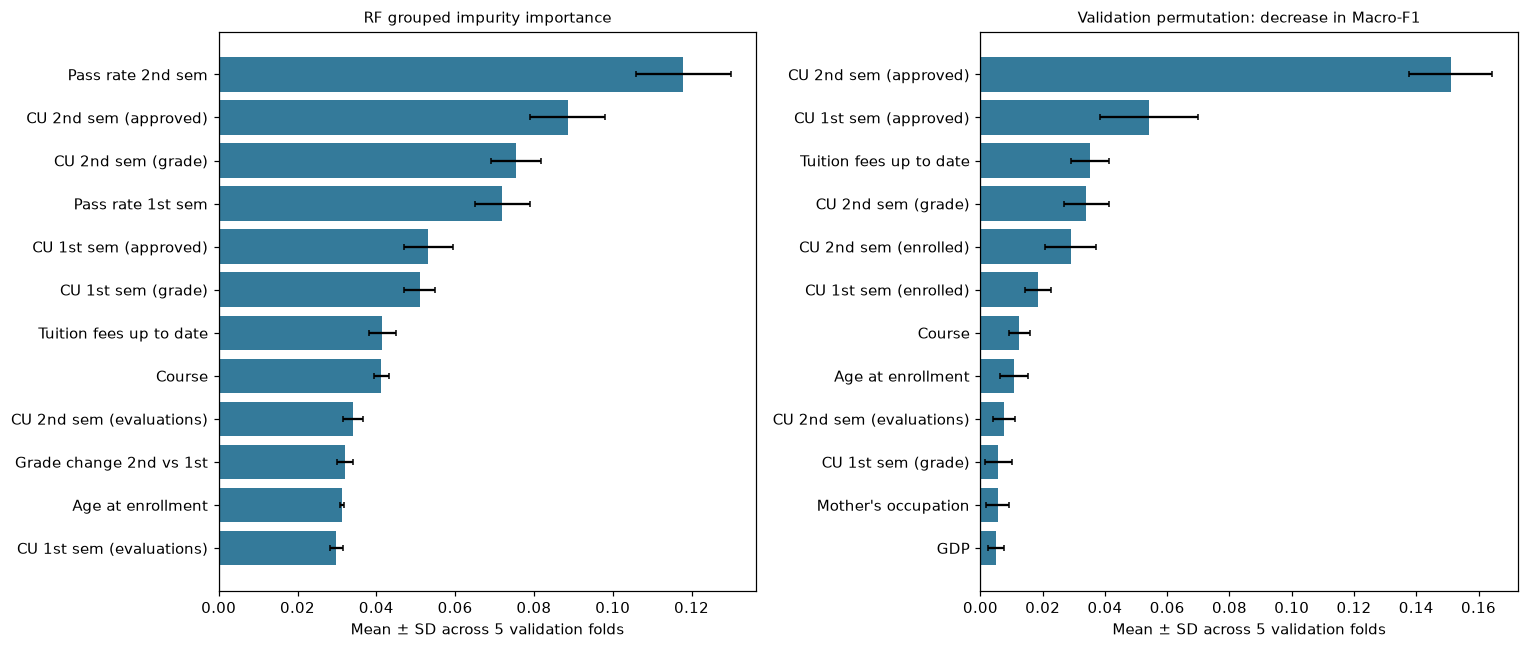

In [4]:
from sklearn.inspection import permutation_importance
from src.features import engineered_columns
importance_rows = []
N_REPEATS = 5
for fold, (tr, va) in enumerate(folds, 1):
    model = make_model("RF", "C")
    model.fit(X.iloc[tr], y.iloc[tr])
    assert np.array_equal(model.predict(X.iloc[va]), oof.loc[X.index[va], "predicted"].to_numpy())
    assert np.allclose(model.predict_proba(X.iloc[va]),
                       oof.loc[X.index[va], [f"prob_{c}" for c in model.classes_]].to_numpy())
    names = get_feature_names(model)
    original = sorted([*X.columns, *engineered_columns("C")], key=len, reverse=True)
    def source_name(name):
        return next(c for c in original if name == c or name.startswith(c + "_"))
    mdi = pd.Series(model.named_steps["clf"].feature_importances_, index=[source_name(n) for n in names]).groupby(level=0).sum()
    assert np.isclose(mdi.sum(), 1)
    for feature, value in mdi.items():
        importance_rows.append({"model": "RF", "feature_set": "C", "method": "impurity_grouped",
                                "fold": fold, "feature": feature, "importance": value,
                                "repeat_std": 0., "n_repeats": 1})
    pi = permutation_importance(model, X.iloc[va], y.iloc[va], scoring="f1_macro",
                                n_repeats=N_REPEATS, random_state=config.RANDOM_STATE + fold,
                                n_jobs=1)
    for i, feature in enumerate(X.columns):
        importance_rows.append({"model": "RF", "feature_set": "C", "method": "permutation_validation",
                                "fold": fold, "feature": feature, "importance": pi.importances_mean[i],
                                "repeat_std": pi.importances_std[i], "n_repeats": N_REPEATS})
    print(f"RF-C: importance fold {fold}/5 hoàn tất", flush=True)

importance = pd.DataFrame(importance_rows)
assert importance.groupby(["method", "feature"]).size().eq(5).all()
assert np.isfinite(importance.select_dtypes("number").to_numpy()).all()
importance.to_csv(REPORTS / "importance.csv", index=False)
rankings = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, method, title in zip(axes, ["impurity_grouped", "permutation_validation"],
                             ["RF grouped impurity importance", "Validation permutation: decrease in Macro-F1"]):
    table = importance.loc[importance.method.eq(method)].groupby("feature").importance.agg(
        mean="mean", std=lambda s: s.std(ddof=0)).sort_values("mean", ascending=False)
    rankings[method] = table
    display(Markdown(f"**{title}**"))
    display(table.head(15).round(5))
    top = table.head(12).iloc[::-1]
    labels = [s.replace("Curricular units ", "CU ") for s in top.index]
    ax.barh(labels, top["mean"], xerr=top["std"], capsize=2, color="#347a9a")
    ax.axvline(0, color="black", linewidth=.7)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Mean ± SD across 5 validation folds")
fig.tight_layout()
capture_figure(fig, "04_rf_validation_importance.png")
plt.show()

## 4. Bàn giao RQ2–RQ4 và cách tái lập

Nhận xét lấy số liệu trực tiếp từ lượt chạy này. Không diễn giải importance như tác động
nhân quả. Chưa có LR đã tuning nên không tự làm thay phần hệ số của SV3;
SVM RBF không có vector hệ số tuyến tính. RF-C là phân tích tham chiếu;
cần cập nhật sau khi nhóm chốt mô hình nếu mô hình cuối khác RF.

In [5]:
count_e = len(enrolled)
n_to_d = int(enrolled.predicted.eq("Dropout").sum())
n_to_g = int(enrolled.predicted.eq("Graduate").sum())
n_correct = count_e - n_to_d - n_to_g
profiles = enrolled.groupby("prediction_group")[profile_cols].median()
approved = "Curricular units 2nd sem (approved)"
grade = "Curricular units 2nd sem (grade)"
interpret_error = (
    f"Trong Enrolled, nhóm bị nhầm Dropout có trung vị số môn đạt kỳ 2 "
    f"{profiles.loc['Enrolled → Dropout', approved]:.0f} và điểm kỳ 2 "
    f"{profiles.loc['Enrolled → Dropout', grade]:.2f}; nhóm đúng tương ứng "
    f"{profiles.loc['Correct Enrolled', approved]:.0f} và "
    f"{profiles.loc['Correct Enrolled', grade]:.2f}. Nhóm bị nhầm Graduate có "
    f"{profiles.loc['Enrolled → Graduate', approved]:.0f} môn đạt và điểm "
    f"{profiles.loc['Enrolled → Graduate', grade]:.2f}. "
    "Mô hình có xu hướng đẩy Enrolled có kết quả học tập thấp về Dropout và "
    "Enrolled có kết quả cao về Graduate. Đây là mô tả sự chồng lấp giữa các lớp "
    "trong dữ liệu, không xác định được kết cục tương lai của sinh viên Enrolled."
)
fee_rows = slice_table.loc[slice_table.group.eq("Tuition fees up to date")].set_index("value")
interpret_groups = (
    f"Trong lớp Enrolled, nhóm học phí chưa cập nhật có tỷ lệ sai "
    f"{fee_rows.loc['0', 'error_rate']:.1%} (n={int(fee_rows.loc['0', 'n_Enrolled'])}), "
    f"so với {fee_rows.loc['1', 'error_rate']:.1%} ở nhóm đã cập nhật "
    f"(n={int(fee_rows.loc['1', 'n_Enrolled'])}). Nhóm nhỏ có biến thiên lớn; "
    "chưa kiểm soát khác biệt về ngành học, tuổi và kết quả học tập nên không "
    "quy kết nguyên nhân hoặc khái quát tỷ lệ này cho toàn bộ sinh viên."
)
interpret_importance = (
    "Permutation xếp số môn đạt kỳ 2, số môn đạt kỳ 1 và tình trạng học phí "
    "ở ba vị trí đầu: các nhóm thông tin này hỗ trợ phân loại RF-C trên validation. "
    "Impurity xếp tỷ lệ đạt kỳ 2 cao nhất. Hai bảng khác nhau vì permutation làm việc "
    "với biến đầu vào gốc, còn impurity có cả biến tạo thêm; các tỷ lệ đạt và số môn "
    "đạt dùng chung thông tin và có tương quan. Không hiểu thứ hạng này là bằng chứng "
    "một biến có thể gây ra bỏ học hoặc một biến xếp thấp có thể bỏ ngay."
)
display(Markdown(f"**Enrolled:** {n_correct}/{count_e} đúng; {n_to_d} nhầm Dropout; {n_to_g} nhầm Graduate.\n\n"
    + interpret_error + "\n\n" + interpret_groups + "\n\n" + interpret_importance))

**Enrolled:** 394/635 đúng; 89 nhầm Dropout; 152 nhầm Graduate.

Trong Enrolled, nhóm bị nhầm Dropout có trung vị số môn đạt kỳ 2 0 và điểm kỳ 2 0.00; nhóm đúng tương ứng 4 và 11.80. Nhóm bị nhầm Graduate có 6 môn đạt và điểm 12.75. Mô hình có xu hướng đẩy Enrolled có kết quả học tập thấp về Dropout và Enrolled có kết quả cao về Graduate. Đây là mô tả sự chồng lấp giữa các lớp trong dữ liệu, không xác định được kết cục tương lai của sinh viên Enrolled.

Trong lớp Enrolled, nhóm học phí chưa cập nhật có tỷ lệ sai 64.7% (n=34), so với 36.4% ở nhóm đã cập nhật (n=601). Nhóm nhỏ có biến thiên lớn; chưa kiểm soát khác biệt về ngành học, tuổi và kết quả học tập nên không quy kết nguyên nhân hoặc khái quát tỷ lệ này cho toàn bộ sinh viên.

Permutation xếp số môn đạt kỳ 2, số môn đạt kỳ 1 và tình trạng học phí ở ba vị trí đầu: các nhóm thông tin này hỗ trợ phân loại RF-C trên validation. Impurity xếp tỷ lệ đạt kỳ 2 cao nhất. Hai bảng khác nhau vì permutation làm việc với biến đầu vào gốc, còn impurity có cả biến tạo thêm; các tỷ lệ đạt và số môn đạt dùng chung thông tin và có tương quan. Không hiểu thứ hạng này là bằng chứng một biến có thể gây ra bỏ học hoặc một biến xếp thấp có thể bỏ ngay.

## 5. File bàn giao và cách chạy lại

- `04_timepoint.ipynb`: so sánh A/B/C; chạy và lưu trước notebook 05.
- `05_error_analysis.ipynb`: lỗi, importance, kiểm tra và xuất minh chứng tại mục 6.
- `../reports/timepoint_cv.csv`: 45 dòng CV; `../reports/rf_oof.csv`: 3.539 dự đoán OOF.
- `../reports/importance.csv`: 375 dòng importance theo fold và độ biến thiên hoán vị.
- `../requirements.txt`: thư viện; chạy notebook 04, lưu lại, rồi chạy notebook 05 để kiểm tra và xuất minh chứng.

Chọn kernel của `.venv`, **Restart & Run All notebook 04, lưu, rồi Restart & Run All
notebook 05 và lưu**. Không cần script chạy riêng. Mục 6 tự chạy pip check, unit test,
kiểm tra RF của Quốc trên train và xuất 4 PNG, 3 CSV, run.log, metadata ra ngoài repo.
Đường dẫn minh chứng được in ở ô đầu và cuối; `status: passed` chỉ xuất hiện khi
toàn bộ kiểm tra đạt. Nếu một ô phân tích lỗi trước mục 6, metadata giữ `running`,
không coi là lượt chạy thành công. RF-C là tham chiếu, chưa thay kết quả test #18.


## 6. Kiểm tra kết quả và xuất minh chứng

Thay cho script chạy riêng. Ô này kiểm tra các biến vừa tính trong kernel 05 và
CSV/provenance từ notebook 04 đã lưu; không đọc output cũ của 05 để nhận là kết quả mới.
Log chứa kiểm tra bàn giao và log của 04; bảng/hình phân tích đầy đủ của 05 nằm trong
output notebook. Không tự chạy lại notebook hoặc đánh giá hold-out.


In [6]:
def verify_and_export():
    with (OUTPUT / "run.log").open("w", encoding="utf-8") as log:
        def emit(message):
            print(message, flush=True)
            log.write(message + "\n")
            log.flush()
        def command(label, args):
            emit("COMMAND " + subprocess.list2cmdline(args))
            result = subprocess.run(args, cwd=ROOT, capture_output=True, text=True,
                                    encoding="utf-8", errors="replace")
            emit(result.stdout + result.stderr)
            METADATA["checks"][label] = {"exit_code": result.returncode}
            if result.returncode:
                raise RuntimeError(label + " failed; xem run.log")
        try:
            emit("SV5 verification: " + RUN_ID)
            command("pip_check", [sys.executable, "-m", "pip", "check"])
            nb04 = nbformat.read(ROOT / "notebooks/04_timepoint.ipynb", as_version=4)
            code_cells = [c for c in nb04.cells if c.cell_type == "code"]
            assert all(c.execution_count is not None for c in code_cells), "Chạy/lưu toàn bộ notebook 04 trước."
            assert not any(o.output_type == "error" for c in code_cells for o in c.outputs)
            markers = [line.removeprefix("SV5_ABC_HANDOFF=")
                       for c in code_cells for o in c.outputs if o.output_type == "stream"
                       for line in o.text.splitlines() if line.startswith("SV5_ABC_HANDOFF=")]
            assert len(markers) == 1, "Chạy và lưu notebook 04 với dấu vết bàn giao mới."
            abc = json.loads(markers[0])
            assert abc["status"] == "passed" and abc["data_sha256"] == DATA_HASH
            assert abc["notebook_code_sha256"] == METADATA["notebook_code_sha256"]["04_timepoint.ipynb"]
            assert abc["provenance"] == PROVENANCE, "04/05 khác dữ liệu, môi trường hoặc cấu hình."
            assert abc["csv_sha256"] == INPUT_CSV_HASHES
            assert all(sha(REPORTS / name) == value for name, value in INPUT_CSV_HASHES.items())
            METADATA["abc_run"] = abc
            for c in code_cells:
                for item in c.outputs:
                    if item.output_type == "stream":
                        emit(item.text.rstrip())
            cv = pd.read_csv(REPORTS / "timepoint_cv.csv")
            saved_oof = pd.read_csv(REPORTS / "rf_oof.csv")
            saved_imp = pd.read_csv(REPORTS / "importance.csv")
            pd.testing.assert_frame_equal(saved_oof.set_index("row_id"), oof)
            pd.testing.assert_frame_equal(saved_imp, importance, check_exact=False, atol=1e-12)
            assert len(cv) == 45 and cv.groupby(["model", "feature_set"]).size().eq(5).all()
            assert set(zip(cv.model, cv.feature_set)) == {(m, f) for m in ["RF", "GB", "SVM"] for f in ["A", "B", "C"]}
            assert cv.data_sha256.eq(DATA_HASH).all()
            assert len(saved_oof) == len(X) and saved_oof.row_id.is_unique
            assert set(saved_oof.row_id) == set(X.index) and not set(saved_oof.row_id) & HOLDOUT_IDS
            assert (saved_oof.actual.to_numpy() == y.loc[saved_oof.row_id].to_numpy()).all()
            probabilities = saved_oof[[f"prob_{c}" for c in config.CLASSES]].to_numpy()
            assert np.isfinite(probabilities).all() and (probabilities >= 0).all() and (probabilities <= 1).all()
            assert np.allclose(probabilities.sum(axis=1), 1)
            assert len(saved_imp) == 375 and saved_imp.groupby(["method", "feature"]).size().eq(5).all()
            assert not any(df.isna().any().any() for df in [cv, saved_oof, saved_imp])
            METADATA["checks"]["output_integrity"] = {"passed": True, "cv_rows": len(cv),
                "oof_rows": len(saved_oof), "importance_rows": len(saved_imp),
                "reserved_holdout_rows": len(HOLDOUT_IDS)}
            METADATA["cv_f1_macro_mean"] = {f"{m}_{f}": float(v) for (m, f), v
                in cv.groupby(["model", "feature_set"]).f1_macro.mean().items()}
            command("existing_tests", [sys.executable, "-X", "utf8", "-B", "-m", "unittest", "discover", "-s", "tests", "-v"])
            import joblib
            rf = joblib.load(ROOT / "models/rf_best.joblib")
            assert rf_source["data_sha256"] == DATA_HASH
            assert all(rf.get_params()[k] == v for k, v in rf_source["best_params"].items())
            probs = rf.predict_proba(X.iloc[:3])
            assert set(rf.classes_) == set(config.CLASSES) and probs.shape == (3, 3)
            assert np.allclose(probs.sum(axis=1), 1)
            METADATA["checks"]["quoc_rf_technical_smoke"] = {"passed": True,
                "rows_from_train": X.index[:3].tolist(), "classes": rf.classes_.tolist(),
                "predictions": rf.predict(X.iloc[:3]).tolist(),
                "note": "Technical checks only; not acceptance of issue #31 or test evaluation."}
            assert MODEL_HASHES == {p.name: sha(p) for p in (ROOT / "models").glob("*.joblib")}
            assert sha(config.DATA_FILE) == DATA_HASH
            assert all(notebook_code_hash(ROOT / "notebooks" / name) == value
                       for name, value in METADATA["notebook_code_sha256"].items())
            images04 = [o.data["image/png"] for c in code_cells for o in c.outputs
                        if "image/png" in o.get("data", {})]
            assert len(images04) == 1
            (OUTPUT / "01_abc_cv.png").write_bytes(base64.b64decode(images04[0]))
            assert set(FIGURE_BYTES) == {"02_rf_oof_confusion.png", "03_enrolled_errors.png", "04_rf_validation_importance.png"}
            for name, data in FIGURE_BYTES.items():
                (OUTPUT / name).write_bytes(data)
            for name in ["timepoint_cv.csv", "rf_oof.csv", "importance.csv"]:
                shutil.copy2(REPORTS / name, OUTPUT / name)
            METADATA["status"] = "passed"
            emit("PASS: output integrity, existing tests, RF technical smoke, models/data unchanged. No hold-out evaluation.")
        except Exception as exc:
            METADATA["status"] = "failed"
            METADATA["error"] = f"{type(exc).__name__}: {exc}"
            emit(METADATA["error"])
            raise
        finally:
            METADATA["finished_at"] = datetime.now(ZoneInfo("Asia/Ho_Chi_Minh")).isoformat()
            METADATA["elapsed_seconds_notebook05"] = round(
                (datetime.fromisoformat(METADATA["finished_at"]) - STARTED).total_seconds(), 3)
            emit("Evidence: " + str(OUTPUT))
            METADATA["artifact_sha256"] = {p.name: sha(p) for p in OUTPUT.iterdir()
                if p.is_file() and p.name != "metadata.json"}
            (OUTPUT / "metadata.json").write_text(
                json.dumps(METADATA, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    display(Markdown(f"**Kiểm tra đạt. Minh chứng:** `{OUTPUT}`. Chờ Hậu kiểm thử chéo."))

verify_and_export()


SV5 verification: 20261115_SV5_ANALYSIS_105647_898466


COMMAND C:\Users\Admin\MLGroup\DoAn_MayHoc\Nhom01-student-dropout\.venv\Scripts\python.exe -m pip check


No broken requirements found.



{
  "python": "3.12.10",
  "versions": {
    "numpy": "2.5.4",
    "pandas": "3.1.1",
    "scipy": "1.18.1",
    "scikit-learn": "1.9.1",
    "joblib": "1.6.0",
    "matplotlib": "3.11.2"
  },
  "data_sha256": "edc197d1381f25414a3757ab9bbae5f1f6d21aa6a964dbe98a148c15f3d63036",
  "seed": 42,
  "folds": 5,
  "train_rows": 3539,
  "holdout_rows_reserved": 885,
  "parameters": {
    "RF": {
      "n_estimators": 100,
      "min_samples_split": 10,
      "min_samples_leaf": 2,
      "max_features": "sqrt",
      "max_depth": null,
      "class_weight": "balanced"
    },
    "GB": {
      "n_estimators": 200,
      "learning_rate": 0.05,
      "max_depth": 4,
      "subsample": 0.85
    },
    "SVM": {
      "C": 10.0,
      "kernel": "rbf",
      "gamma": 0.003,
      "class_weight": "balanced"
    }
  },
  "source_sha256": {
    "src\\config.py": "46c4bc6cf6dbaf484eb7e40bb182dd544bdcc24f55c24cd47e373689c1de402b",
    "src\\data.py": "5923ac69745b8dbc392f862d9e70c0ca1aa153bcd222e1db6ebeacc2

RF-A: 5 fold hoàn tất (7.6s)


GB-A: 5 fold hoàn tất (48.1s)


... (10 outputs left out)

Fitting 5 folds for each of 1 candidates, totalling 5 fits
test_feature_sets_and_unknown_category (test_random_forest.RandomForestTests.test_feature_sets_and_unknown_category) ... ok
test_search_curve_and_model_roundtrip (test_random_forest.RandomForestTests.test_search_curve_and_model_roundtrip) ... ok
test_colliding_names_fail_clearly (test_shared_pipeline.DataTests.test_colliding_names_fail_clearly) ... ok
test_shared_split_and_timepoints (test_shared_pipeline.DataTests.test_shared_split_and_timepoints) ... ok
test_source_aliases_and_string_paths (test_shared_pipeline.DataTests.test_source_aliases_and_string_paths) ... ok
test_reordered_and_extra_columns_and_empty_file (test_shared_pipeline.LoggingTests.test_reordered_and_extra_columns_and_empty_file) ... ok
test_mi_uses_discrete_mask (test_shared_pipeline.PreprocessingTests.test_mi_uses_discrete_mask) ... ok
test_selection_fit_and_feature_names (test_shared_pipeline.PreprocessingTests.test_selection_fit_and_feature_names) ... ok
te

PASS: output integrity, existing tests, RF technical smoke, models/data unchanged. No hold-out evaluation.

Evidence: C:\Users\Admin\Documents\MLGroup_SV5\runs\20261115_SV5_ANALYSIS_105647_898466


**Kiểm tra đạt. Minh chứng:** `C:\Users\Admin\Documents\MLGroup_SV5\runs\20261115_SV5_ANALYSIS_105647_898466`. Chờ Hậu kiểm thử chéo.